In [34]:
#step 1: install scikit-learn for building the prediction model
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [35]:
#step 2a: load the libraries and the CSV files needed for the model
import pandas as pd
from pathlib import Path

data_dir = Path("../Baseball/lahman_1871-2025_csv")

people = pd.read_csv(data_dir / "People.csv", encoding="utf-8-sig")
batting = pd.read_csv(data_dir / "Batting.csv")
pitching = pd.read_csv(data_dir / "Pitching.csv")
appearances = pd.read_csv(data_dir / "Appearances.csv")
awards = pd.read_csv(data_dir / "AwardsPlayers.csv")
allstar = pd.read_csv(data_dir / "AllstarFull.csv")
hof = pd.read_csv(data_dir / "HallOfFame.csv")

**What this step did:** It loaded 7 files from the Lahman baseball database into tables (called DataFrames) that we can work with:

| Table | What's in it |
|---|---|
| `people` | Every player's name and basic info |
| `batting` | Hitting stats, one row per player per season |
| `pitching` | Pitching stats, one row per player per season |
| `appearances` | How many games each player played at each position, per season |
| `awards` | Awards won (MVP, Cy Young, Gold Glove, etc.) |
| `allstar` | All-Star Game selections |
| `hof` | Every Hall of Fame ballot and whether the player was inducted |

**Result:** This cell shows no output. That's normal: it only loads the data into memory.

In [36]:
#step 2b: build one row of career stats per player

#career batting totals and rate stats
bat_cols = ["G", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "BB", "SO", "HBP", "SF"]
career_bat = batting.groupby("playerID")[bat_cols].sum()

career_bat["AVG"] = career_bat["H"] / career_bat["AB"]
career_bat["OBP"] = (career_bat["H"] + career_bat["BB"] + career_bat["HBP"]) / (
    career_bat["AB"] + career_bat["BB"] + career_bat["HBP"] + career_bat["SF"]
)
singles = career_bat["H"] - career_bat["2B"] - career_bat["3B"] - career_bat["HR"]
total_bases = singles + 2 * career_bat["2B"] + 3 * career_bat["3B"] + 4 * career_bat["HR"]
career_bat["SLG"] = total_bases / career_bat["AB"]
career_bat["OPS"] = career_bat["OBP"] + career_bat["SLG"]

#career pitching totals and rate stats (prefixed with P_ to avoid clashing with batting columns)
pit_cols = ["W", "L", "G", "GS", "SV", "IPouts", "H", "ER", "BB", "SO", "SHO"]
career_pit = pitching.groupby("playerID")[pit_cols].sum()

career_pit["IP"] = career_pit["IPouts"] / 3
career_pit["ERA"] = 9 * career_pit["ER"] / career_pit["IP"]
career_pit["WHIP"] = (career_pit["BB"] + career_pit["H"]) / career_pit["IP"]
career_pit = career_pit.add_prefix("P_")

#count seasons played and decide if each player was mainly a pitcher
seasons = appearances.groupby("playerID")["yearID"].agg(seasons="nunique", first_year="min", last_year="max")
games = appearances.groupby("playerID")[["G_all", "G_p"]].sum()
seasons["is_pitcher"] = games["G_p"] > games["G_all"] / 2

#count major awards and All-Star selections
award_names = {
    "Most Valuable Player": "MVP",
    "Cy Young Award": "CyYoung",
    "Gold Glove": "GoldGlove",
    "Silver Slugger": "SilverSlugger",
    "Rookie of the Year": "ROY",
}
award_counts = (
    awards[awards["awardID"].isin(award_names)]
    .assign(award=lambda df: df["awardID"].map(award_names))
    .pivot_table(index="playerID", columns="award", values="yearID", aggfunc="count", fill_value=0)
)
allstar_counts = allstar.groupby("playerID")["yearID"].nunique().rename("AllStar")

#combine everything into one career table
career = (
    people.set_index("playerID")[["nameFirst", "nameLast"]]
    .join(seasons, how="inner")
    .join(career_bat)
    .join(career_pit)
    .join(award_counts)
    .join(allstar_counts)
)
count_cols = list(award_counts.columns) + ["AllStar"]
career[count_cols] = career[count_cols].fillna(0).astype(int)

career.head()

,nameFirst,nameLast,seasons,first_year,last_year,is_pitcher,G,AB,R,H,...,P_SHO,P_IP,P_ERA,P_WHIP,CyYoung,GoldGlove,MVP,ROY,SilverSlugger,AllStar
playerID,,,,,,,,,,,,,,,,,,,,,
aardsda01,David,Aardsma,9,2004,2015,True,331,4,0,0,...,0.0,337.000000,4.272997,1.421365,0,0,0,0,0,0
aaronha01,Hank,Aaron,23,1954,1976,False,3298,12364,2174,3771,...,NaN,NaN,NaN,NaN,0,3,1,0,0,21
aaronto01,Tommie,Aaron,7,1962,1971,False,437,944,102,216,...,NaN,NaN,NaN,NaN,0,0,0,0,0,0
aasedo01,Don,Aase,13,1977,1990,True,448,5,0,0,...,5.0,1109.333333,3.796875,1.390024,0,0,0,0,0,1
abadan01,Andy,Abad,3,2001,2006,False,15,21,1,2,...,NaN,NaN,NaN,NaN,0,0,0,0,0,0


**What this step did:** The raw stats have one row per *season*. Hall of Fame voters judge a whole *career*, so this step added up each player's seasons into **one row per player**, a table called `career`. It includes:

- **Hitting totals** (hits, home runs, RBI, and so on), plus career batting average (AVG), on-base percentage (OBP), slugging (SLG), and OPS (OBP + SLG, a common all-around hitting measure)
- **Pitching totals** (wins, strikeouts, saves, and so on), plus career ERA and WHIP. These columns start with `P_` so they don't get mixed up with hitting columns.
- **Career length:** number of seasons and first and last year played
- **`is_pitcher`:** True if the player spent more than half their games pitching
- **Honors:** counts of MVPs, Cy Youngs, Gold Gloves, Silver Sluggers, Rookie of the Year awards, and All-Star selections

**Result:** The table shows the first 5 players alphabetically. A few things to notice:
- Hank Aaron has 23 seasons, 3,771 hits and 21 All-Star selections, but his pitching columns show `NaN` ("not a number," meaning blank) because he never pitched.
- David Aardsma, a pitcher, has 4 at-bats and 0 hits. Pitchers rarely bat, so their hitting stats are tiny.
- This is why we'll study hitters and pitchers separately.

In [37]:
#step 3: add the Hall of Fame label and keep only eligible players

#target: 1 if the player was inducted as a player (by any committee), else 0
inducted = hof[(hof["category"] == "Player") & (hof["inducted"] == "Y")]
career["inducted"] = career.index.isin(inducted["playerID"]).astype(int)

#eligible for the ballot: 10+ seasons played and retired at least 5 years
last_data_year = career["last_year"].max()
eligible = career[(career["seasons"] >= 10) & (career["last_year"] <= last_data_year - 5)]

#split into separate tables for hitters and pitchers
hitters = eligible[~eligible["is_pitcher"]]
pitchers = eligible[eligible["is_pitcher"]]

print(f"All players: {len(career):,}")
print(f"Eligible players: {len(eligible):,} ({eligible['inducted'].sum()} inducted)")
print(f"Hitters: {len(hitters):,} ({hitters['inducted'].sum()} inducted, {hitters['inducted'].mean():.1%})")
print(f"Pitchers: {len(pitchers):,} ({pitchers['inducted'].sum()} inducted, {pitchers['inducted'].mean():.1%})")

All players: 24,011
Eligible players: 3,666 (278 inducted)
Hitters: 2,318 (197 inducted, 8.5%)
Pitchers: 1,348 (81 inducted, 6.0%)


**What this step did:** It did three things:
1. **Added the answer the model will learn to predict.** A new column, `inducted`, is 1 if the player is in the Hall of Fame as a player and 0 if not.
2. **Kept only players who could have been voted in.** The Hall of Fame requires at least **10 seasons** and at least **5 years of retirement**. Players who don't meet both rules were removed. Without this, the data would be flooded with thousands of short-career players who were never real candidates.
3. **Split the players into `hitters` and `pitchers`,** since they're judged on completely different stats.

**Result:**
- Of the **24,011** players in history, **3,666** are eligible, and **278** of them were inducted.
- **Hitters:** 2,318 eligible, 197 inducted (**8.5%**)
- **Pitchers:** 1,348 eligible, 81 inducted (**6.0%**)

**Why it matters:** Even among eligible players, only about 1 in 12 gets in. A lazy model could predict "No" for everyone and be right about 92% of the time while being useless. That's why we'll judge the model by how well it finds the actual Hall of Famers, not by overall accuracy.

In [38]:
#step 4a: compare typical (median) career stats for inductees vs non-inductees
hitter_stats = ["seasons", "H", "HR", "RBI", "R", "SB", "AVG", "OBP", "SLG", "OPS", "AllStar", "MVP", "GoldGlove"]
pitcher_stats = ["seasons", "P_W", "P_L", "P_SV", "P_IP", "P_SO", "P_ERA", "P_WHIP", "P_SHO", "AllStar", "CyYoung"]

def compare_groups(df, stats):
    medians = df.groupby("inducted")[stats].median().T
    medians.columns = ["Not inducted", "Inducted"]
    #correlation with the inducted label: how strongly each stat lines up with induction
    medians["Correlation"] = df[stats].corrwith(df["inducted"])
    return medians.sort_values("Correlation", ascending=False).round(3)

print("Hitters")
display(compare_groups(hitters, hitter_stats))
print("Pitchers")
display(compare_groups(pitchers, pitcher_stats))

Hitters


,Not inducted,Inducted,Correlation
R,498.000,1261.000,0.521
RBI,435.000,1175.000,0.514
H,1004.000,2314.000,0.499
AllStar,0.000,6.000,0.493
seasons,12.000,18.000,0.443
AVG,0.265,0.306,0.421
OPS,0.721,0.846,0.412
OBP,0.332,0.378,0.398
SLG,0.386,0.467,0.371
MVP,0.000,0.000,0.364


Pitchers


,Not inducted,Inducted,Correlation
P_W,80.000,246.000,0.541
P_SHO,6.000,35.000,0.523
P_IP,1428.667,3590.333,0.496
P_SO,774.000,1978.000,0.489
AllStar,0.000,5.000,0.456
P_L,82.000,166.000,0.394
seasons,12.000,18.000,0.393
CyYoung,0.000,0.000,0.296
P_SV,10.000,16.000,0.107
P_ERA,3.840,3.029,-0.331


**What this step did:** It compared the **typical (median)** Hall of Famer with the typical non-Hall of Famer on each stat. The median is the middle value, so one extreme player can't skew it. The table also shows a **correlation** score for each stat, which measures how closely it lines up with getting inducted:
- Close to **1**: the higher the stat, the more likely a player is inducted
- Close to **0**: the stat doesn't say much
- **Negative**: lower is better, as with ERA

The tables are sorted from most to least useful.

**Result for hitters:**
- The best signs are **runs (0.52), RBI (0.51), hits (0.50) and All-Star selections (0.49)**. The typical Hall of Famer has about **2,300 hits**, compared with about 1,000 for everyone else, and has **6 All-Star selections** against 0.
- Big career totals matter more than averages. Batting average (0.42) and OPS (0.41) help, but less.
- Surprisingly, **home runs (0.34)** are a weaker sign than hits.
- MVP and Gold Glove have a median of 0 for both groups because most players, even most Hall of Famers, never won one. A player who has won one still gets a boost.

**Result for pitchers:**
- The best signs are **wins (0.54), shutouts (0.52), innings pitched (0.50) and strikeouts (0.49)**. The typical Hall of Fame pitcher has **246 wins**, compared with 80.
- **ERA (−0.33)** is negative because a lower ERA is better: Hall of Famers average about 3.03 vs 3.84.
- **Saves (0.11)** barely matter, so relief pitchers have a hard time getting in.

**In plain terms:** Voters reward **long, productive careers** more than a few great seasons.

In [39]:
#step 4b: induction rate for players who reached famous career milestones
milestones = {
    "3,000 hits": (hitters, hitters["H"] >= 3000),
    "500 home runs": (hitters, hitters["HR"] >= 500),
    ".300 average (5,000+ AB)": (hitters, (hitters["AVG"] >= 0.300) & (hitters["AB"] >= 5000)),
    "300 wins": (pitchers, pitchers["P_W"] >= 300),
    "3,000 strikeouts": (pitchers, pitchers["P_SO"] >= 3000),
    "300 saves": (pitchers, pitchers["P_SV"] >= 300),
}

rows = []
for name, (group, reached) in milestones.items():
    players = group[reached]
    left_out = players[players["inducted"] == 0]
    rows.append({
        "Milestone": name,
        "Players": len(players),
        "Inducted": players["inducted"].sum(),
        "Induction rate": f"{players['inducted'].mean():.0%}",
        "Not inducted (first 8)": ", ".join((left_out["nameFirst"] + " " + left_out["nameLast"]).head(8)),
    })

pd.DataFrame(rows).set_index("Milestone")

,Players,Inducted,Induction rate,Not inducted (first 8)
Milestone,,,,
"3,000 hits",31,28,90%,"Rafael Palmeiro, Alex Rodriguez, Pete Rose"
500 home runs,26,19,73%,"Barry Bonds, Mark McGwire, Rafael Palmeiro, Ma..."
".300 average (5,000+ AB)",132,87,66%,"Matty Alou, Moises Alou, Ginger Beaumont, Wall..."
300 wins,24,23,96%,Roger Clemens
"3,000 strikeouts",17,15,88%,"Roger Clemens, Curt Schilling"
300 saves,28,8,29%,"Rick Aguilera, Francisco Cordero, John Franco,..."


**What this step did:** It checked famous career milestones, the round numbers fans and voters talk about, to see what percentage of players who reached each one made the Hall of Fame. It also lists who reached the milestone but *didn't* get in.

**Result:**

| Milestone | Made the Hall | Who's missing |
|---|---|---|
| 300 wins | **96%** (23 of 24) | Roger Clemens |
| 3,000 hits | **90%** (28 of 31) | Pete Rose, Rafael Palmeiro, Alex Rodriguez |
| 3,000 strikeouts | **88%** (15 of 17) | Roger Clemens, Curt Schilling |
| 500 home runs | **73%** (19 of 26) | Barry Bonds, Mark McGwire, Sammy Sosa, Manny Ramirez, and others |
| .300 career average | **66%** (87 of 132) | Many players with shorter or less famous careers |
| 300 saves | **29%** (8 of 28) | Most closers |

**What it means:**
- Reaching 300 wins, 3,000 hits or 3,000 strikeouts is almost a guaranteed ticket in.
- Nearly everyone who reached a big milestone and was left out is linked to **steroids/PEDs** (Bonds, Clemens, A-Rod, McGwire, Sosa, Palmeiro, Ramirez) or was **banned** (Pete Rose, for betting on games). They were kept out for reasons that have nothing to do with their stats.
- **300 saves** is not a ticket in. Voters don't value closers as much.

**Why it matters for the model:** A model that only sees stats will predict these players should be in. When it "gets them wrong," it's really showing voter decisions that aren't about performance.

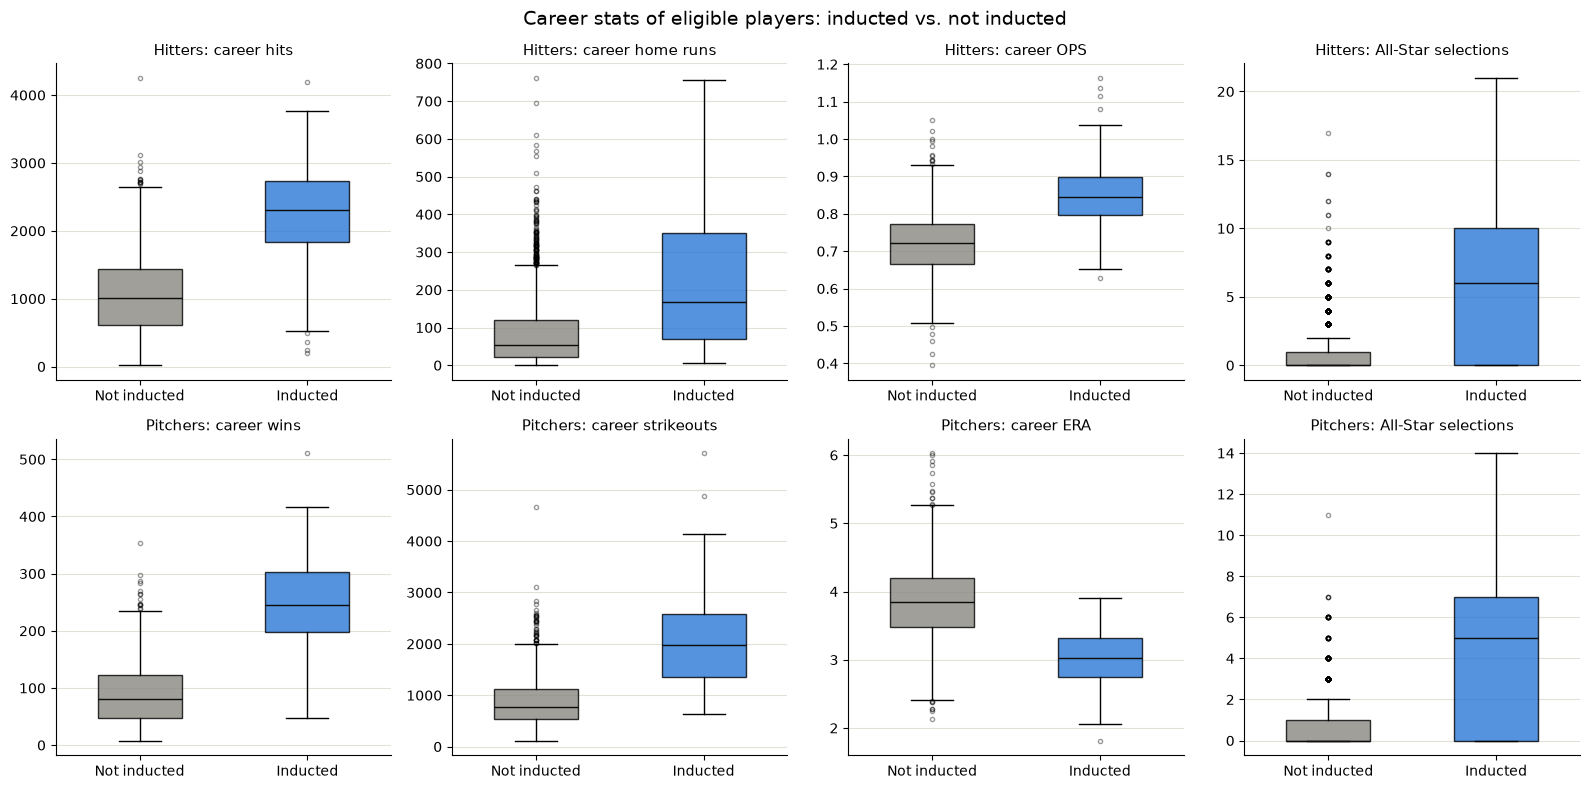

In [40]:
#step 4c: box plots showing how inductees separate from non-inductees on key stats
import matplotlib.pyplot as plt

colors = {"Not inducted": "#898781", "Inducted": "#2a78d6"}
plots = [
    (hitters, "H", "Hitters: career hits"),
    (hitters, "HR", "Hitters: career home runs"),
    (hitters, "OPS", "Hitters: career OPS"),
    (hitters, "AllStar", "Hitters: All-Star selections"),
    (pitchers, "P_W", "Pitchers: career wins"),
    (pitchers, "P_SO", "Pitchers: career strikeouts"),
    (pitchers, "P_ERA", "Pitchers: career ERA"),
    (pitchers, "AllStar", "Pitchers: All-Star selections"),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (df, stat, title) in zip(axes.flat, plots):
    groups = [df.loc[df["inducted"] == 0, stat].dropna(), df.loc[df["inducted"] == 1, stat].dropna()]
    box = ax.boxplot(groups, tick_labels=list(colors), patch_artist=True, widths=0.5,
                     medianprops={"color": "#0b0b0b"}, flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    for patch, color in zip(box["boxes"], colors.values()):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("Career stats of eligible players: inducted vs. not inducted", fontsize=14)
fig.tight_layout()
plt.show()

**What this step did:** It drew **box plots** comparing Hall of Famers (blue) with everyone else (gray) on 8 key stats.

**How to read a box plot:**
- The **box** holds the middle 50% of players.
- The **line inside the box** is the median, the typical player.
- The **whiskers** (thin lines) show the normal range.
- The **dots** are outliers, players far above or below the rest.

**Result:**
- **Hits, wins and strikeouts:** The blue and gray boxes barely overlap. A typical Hall of Famer has more than double the career totals of a typical non-member. These will be the model's most useful stats.
- **OPS:** Hall of Famers are clearly higher (around .850 vs .720), but there's more overlap. Plenty of good hitters had a strong OPS without a long enough career.
- **ERA:** The blue box is *lower* because a lower ERA is better.
- **All-Star selections:** Most non-members were never All-Stars (their box sits at 0). Most Hall of Famers were selected several times.
- **Home runs:** Many gray dots sit high on the chart. There are 20 eligible hitters with 400+ home runs who are not in the Hall. The top of that list (Bonds, A-Rod, Sosa, McGwire, Palmeiro, Ramirez) is linked to PEDs. The rest are mostly power hitters with otherwise weaker résumés, like Adam Dunn and Dave Kingman. Home runs alone don't get a player in.

**In plain terms:** On most of these stats, you can tell the two groups apart at a glance, which is a good sign that a prediction model will work well.

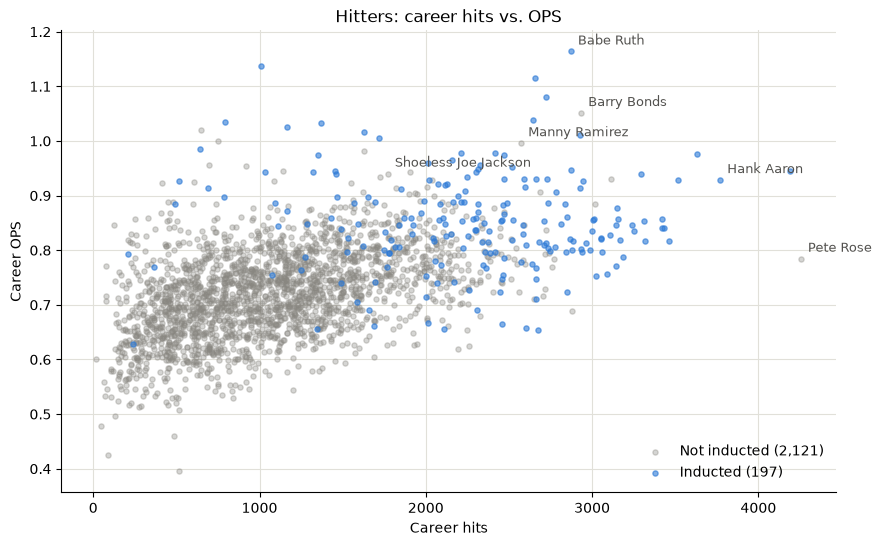

In [41]:
#step 4d: hits vs. OPS for hitters, colored by induction, to see where the Hall of Fame line falls
fig, ax = plt.subplots(figsize=(10, 6))
for label, value in [("Not inducted", 0), ("Inducted", 1)]:
    group = hitters[hitters["inducted"] == value]
    ax.scatter(group["H"], group["OPS"], s=14, alpha=0.6 if value else 0.35,
               color=colors[label], label=f"{label} ({len(group):,})")

#label a few well-known players who are outliers
for player_id in ["rosepe01", "bondsba01", "jacksjo01", "ramirma02", "aaronha01", "ruthba01"]:
    if player_id in hitters.index:
        p = hitters.loc[player_id]
        ax.annotate(f"{p['nameFirst']} {p['nameLast']}", (p["H"], p["OPS"]), xytext=(5, 5),
                    textcoords="offset points", fontsize=9, color="#52514e")

ax.set_xlabel("Career hits")
ax.set_ylabel("Career OPS")
ax.set_title("Hitters: career hits vs. OPS")
ax.legend(frameon=False)
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

**What this step did:** It drew a **scatter plot** of every eligible hitter, with one dot per player:
- **Left to right:** career hits (how *long* and productive the career was)
- **Bottom to top:** career OPS (how *good* a hitter they were per at-bat)
- **Blue dots** are Hall of Famers and **gray dots** are not.

**Result:**
- Blue dots cluster in the **upper right**: players with long careers *and* strong hitting. Above roughly **2,500 hits with an OPS over .800**, most players are in the Hall.
- The lower left is almost entirely gray: shorter careers and average hitting.
- Several labeled players sit deep in "Hall of Fame territory" but are gray:
  - **Pete Rose:** the all-time hits leader, banned for betting on baseball
  - **Barry Bonds** and **Manny Ramirez:** elite numbers, linked to PEDs
  - **"Shoeless" Joe Jackson:** banned after the 1919 Black Sox scandal
- A few blue dots appear on the far left, with under 1,000 hits. All of them are **Negro League stars** like Buck Leonard, Martín Dihigo and Leon Day. Negro League seasons were shorter and many records were lost, so their numbers here understate how good they were.

**In plain terms:** Career length and hitting quality together are a strong guide to who gets in. The exceptions are mostly about off-the-field issues or missing records, not performance.

In [42]:
#step 5a: remove players whose Hall of Fame outcome was not decided by their stats

#Negro League players: their records are incomplete, so their stats understate how good they were
#(a player counts as Negro League if most of their games were in Negro League teams, so Willie Mays and Jackie Robinson stay in)
negro_leagues = ["NNL", "NN2", "NAL", "ECL", "EWL", "NSL", "ANL", "EAS", "IND", "WES", "INT"]
negro_games = appearances[appearances["lgID"].isin(negro_leagues)].groupby("playerID")["G_all"].sum()
negro_share = (negro_games / games["G_all"]).reindex(career.index).fillna(0)
negro_league_players = negro_share[negro_share > 0.5].index

#players kept out because of PEDs (suspended, admitted use, or named in the Mitchell Report)
ped_players = [
    "bondsba01", "clemero02", "rodrial01", "sosasa01", "mcgwima01", "palmera01", "ramirma02",
    "sheffga01", "braunry02", "pettian01", "giambja01", "cansejo01", "gonzaju03", "tejadmi01",
]
#players banned from baseball (Pete Rose for betting, Black Sox for fixing the 1919 World Series)
banned_players = ["rosepe01", "jacksjo01", "cicoted01", "willile01", "weavebu01", "felscha01"]

excluded = set(negro_league_players) | set(ped_players) | set(banned_players)
model_hitters = hitters[~hitters.index.isin(excluded)]

print(f"Eligible hitters: {len(hitters):,}")
print(f"  Negro League players removed: {hitters.index.isin(negro_league_players).sum()}")
print(f"  PED or banned players removed: {hitters.index.isin(ped_players + banned_players).sum()}")
print(f"Hitters left for the model: {len(model_hitters):,} ({model_hitters['inducted'].sum()} inducted)")

Eligible hitters: 2,318
  Negro League players removed: 212
  PED or banned players removed: 14
Hitters left for the model: 2,092 (176 inducted)


**What this step did:** It removed players whose Hall of Fame result had little to do with their stats. Leaving them in would teach the model the wrong lessons.

- **Negro League players:** Many of their records were lost and their seasons were shorter, so their numbers look small even for all-time greats. A player is only removed if *most* of their games were in the Negro Leagues. Stars like Willie Mays and Jackie Robinson, who played briefly in the Negro Leagues before long MLB careers, stay in.
- **PED players:** Players suspended for, admitted to, or named in the Mitchell Report for performance-enhancing drugs (Bonds, A-Rod, Sosa, McGwire, Palmeiro, Ramirez, and others). Voters have kept them out despite their numbers.
- **Banned players:** Pete Rose (betting on baseball) and the 1919 "Black Sox" (fixing the World Series), who aren't allowed on the ballot.

**Result:**
- **212** Negro League hitters and **14** PED or banned hitters were removed.
- **2,092** hitters remain, **176** of them in the Hall of Fame.
- Some names on the lists (like Roger Clemens) are pitchers, so they aren't counted here. They'll matter when we build the pitcher model.

In [43]:
#step 5b: split players by era and train a logistic regression model
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

features = ["seasons", "H", "HR", "RBI", "R", "SB", "AVG", "OBP", "SLG", "AllStar", "MVP", "GoldGlove"]

#players who retired after 2010 may still be voted in, so their outcome isn't settled yet
settled = model_hitters[model_hitters["last_year"] <= 2010]
pending = model_hitters[model_hitters["last_year"] > 2010]

#train on older players, test on newer players the model has never seen
train = settled[settled["last_year"] <= 1985]
test = settled[settled["last_year"] > 1985]

print(f"Training set (retired 1985 or earlier): {len(train):,} players, {train['inducted'].sum()} inducted")
print(f"Test set (retired 1986-2010): {len(test):,} players, {test['inducted'].sum()} inducted")
print(f"Not yet decided (retired after 2010): {len(pending):,} players")

#StandardScaler puts every stat on the same scale; class_weight="balanced" makes the rare Hall of Famers count more
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(train[features], train["inducted"])

Training set (retired 1985 or earlier): 1,183 players, 130 inducted
Test set (retired 1986-2010): 637 players, 35 inducted
Not yet decided (retired after 2010): 272 players


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['seasons','H','HR',...,'AllStar','MVP','GoldGlove']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


**What this step did:** It trained the prediction model, a **logistic regression**. The model looks at a player's career stats and gives back a score from 0 to 1 for how much the player looks like a Hall of Famer.

To test it fairly, the players were split by **when they retired**:
- **Training set (retired 1985 or earlier):** 1,183 players, 130 inducted. The model learns from these.
- **Test set (retired 1986–2010):** 637 players, 35 inducted. The model never sees these during training, so they show how it does on a new generation of players.
- **Not yet decided (retired after 2010):** 272 players. Some are still on the ballot or could be added later by a committee, so we can't treat "not inducted" as final for them. The model doesn't learn from them; we'll make predictions for them in step 5f.

Two settings help the model:
- **StandardScaler** puts every stat on the same scale. Without it, a stat measured in thousands (hits) would drown out one measured in decimals (batting average).
- **class_weight="balanced"** makes each Hall of Famer count more during training. Only about 1 in 10 players is inducted, and without this setting the model would learn to just say "No."

**Result:** The output shows the model was built. The test is in the next step.

In [44]:
#step 5c: check how well the model predicts the test players
from sklearn.metrics import confusion_matrix, precision_score, recall_score, average_precision_score

test = test.assign(probability=model.predict_proba(test[features])[:, 1])
test["predicted"] = (test["probability"] >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(test["inducted"], test["predicted"]).ravel()
print(f"Hall of Famers correctly found:      {tp} of {tp + fn}")
print(f"Hall of Famers missed:               {fn}")
print(f"Non-members wrongly flagged as HOF:  {fp} of {fp + tn}")
print(f"Non-members correctly ruled out:     {tn}")
print()
print(f"Recall (share of real Hall of Famers found): {recall_score(test['inducted'], test['predicted']):.0%}")
print(f"Precision (share of 'yes' predictions that were right): {precision_score(test['inducted'], test['predicted']):.0%}")
print(f"PR-AUC (overall ranking quality, 1.0 is perfect): {average_precision_score(test['inducted'], test['probability']):.2f}")

Hall of Famers correctly found:      35 of 35
Hall of Famers missed:               0
Non-members wrongly flagged as HOF:  64 of 602
Non-members correctly ruled out:     538

Recall (share of real Hall of Famers found): 100%
Precision (share of 'yes' predictions that were right): 35%
PR-AUC (overall ranking quality, 1.0 is perfect): 0.91


**What this step did:** It asked the model about the 637 test players it had never seen. Any player with a score of 0.5 or higher counts as a "yes" prediction. Then it compared those predictions with what really happened.

**Result:**

| | Model said **Yes** | Model said **No** |
|---|---|---|
| **Actually in the Hall** | 35 ✅ | 0 ❌ |
| **Not in the Hall** | 64 ❌ | 538 ✅ |

- **Recall: 100%.** The model found **every one** of the 35 Hall of Famers. It didn't miss anyone.
- **Precision: 35%.** It said "yes" to 99 players, and about 1 in 3 of them were actually inducted. The other 64 were false alarms.
- **PR-AUC: 0.91.** This measures how well the model *ranks* players, without picking a cutoff. 1.0 would mean every Hall of Famer was ranked above every non-member. 0.91 is strong.

**In plain terms:** The model is very good at finding Hall of Famers but too generous: it also flags a lot of "very good but not quite" players. Part of this is by design, since "balanced" weighting tells the model that missing a Hall of Famer is worse than a false alarm. The scores work best as a **ranking** (higher means more Hall-worthy), not as exact percentages. Step 5e looks at who the false alarms are.

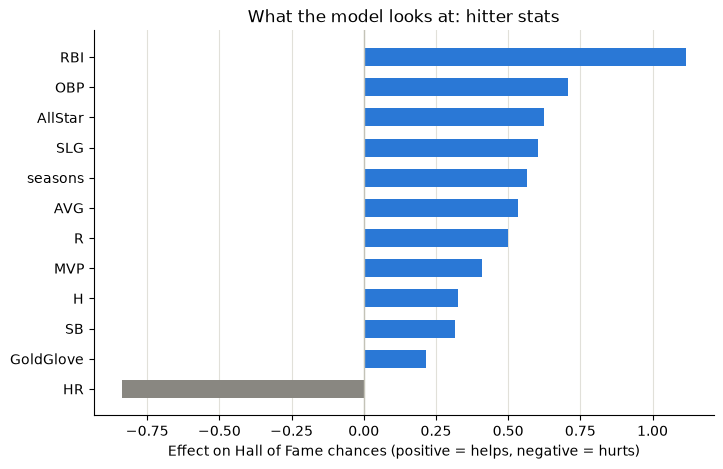

In [45]:
#step 5d: which stats does the model rely on most?
coefs = pd.Series(model[-1].coef_[0], index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coefs.index, coefs.values, color=["#898781" if v < 0 else "#2a78d6" for v in coefs.values], height=0.6)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Effect on Hall of Fame chances (positive = helps, negative = hurts)")
ax.set_title("What the model looks at: hitter stats")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

**What this step did:** It charted how much weight the model gives each stat. A longer blue bar means the stat pushes a player's score up more. A gray bar to the left means the stat pulls the score down when everything else stays the same.

**Result:**
- **RBI** has by far the most weight (1.11), followed by **OBP** (0.71), **All-Star selections** (0.62), **slugging** (0.60) and **seasons played** (0.57). Voters reward players who drove in runs, got on base, were recognized as stars, and lasted a long time.
- **Gold Gloves** (0.21) count the least, so defense matters less to voters than hitting.
- **Home runs show as negative (−0.84), but that does *not* mean home runs hurt.** Home runs overlap heavily with RBI and slugging; a player who hits many homers almost always has high RBI and slugging too. The model gives the credit for power to RBI and slugging. The negative bar means: *between two players with the same RBI and slugging, the one who got there with more homers and less of everything else looks a bit less Hall-worthy.* This matches step 4c, where many 400-homer players with otherwise thin résumés didn't make it.

**In plain terms:** Read this chart as "what the model leans on," not "what each stat is worth alone." Stats that overlap share credit in ways that can look strange.

In [46]:
#step 5e: look at the test players the model got wrong, and how close the calls were
show_cols = ["nameFirst", "nameLast", "last_year", "H", "HR", "AVG", "OPS", "AllStar", "probability"]

print("Highest-rated players who did NOT make it (false alarms):")
display(test[test["inducted"] == 0].sort_values("probability", ascending=False)[show_cols].head(10).round(3))

print("Lowest-rated players who DID make it:")
display(test[test["inducted"] == 1].sort_values("probability")[show_cols].head(5).round(3))

print("How many players the model flags at different probability cutoffs:")
cutoffs = []
for cutoff in [0.5, 0.7, 0.8, 0.9]:
    flagged = test[test["probability"] >= cutoff]
    cutoffs.append({
        "Cutoff": f"{cutoff:.0%}",
        "Players flagged": len(flagged),
        "Actually inducted": flagged["inducted"].sum(),
        "Hall of Famers missed": test["inducted"].sum() - flagged["inducted"].sum(),
    })
display(pd.DataFrame(cutoffs).set_index("Cutoff"))

Highest-rated players who did NOT make it (false alarms):


,nameFirst,nameLast,last_year,H,HR,AVG,OPS,AllStar,probability
playerID,,,,,,,,,
hernake01,Keith,Hernandez,1990,2182,162,0.296,0.821,5,0.996
garvest01,Steve,Garvey,1987,2599,272,0.294,0.775,10,0.991
loftoke01,Kenny,Lofton,2007,2428,130,0.299,0.794,6,0.986
mattido01,Don,Mattingly,1995,2153,222,0.307,0.830,6,0.983
murphda05,Dale,Murphy,1993,2111,398,0.265,0.815,7,0.980
francju01,Julio,Franco,2007,2586,173,0.298,0.782,3,0.973
lynnfr01,Fred,Lynn,1990,1960,306,0.283,0.845,9,0.970
willibe02,Bernie,Williams,2006,2336,287,0.297,0.858,5,0.962
mcgeewi01,Willie,McGee,1999,2254,79,0.295,0.729,4,0.958


Lowest-rated players who DID make it:


,nameFirst,nameLast,last_year,H,HR,AVG,OPS,AllStar,probability
playerID,,,,,,,,,
cartega01,Gary,Carter,1992,2092,324,0.262,0.773,11,0.843
mcgrifr01,Fred,McGriff,2004,2490,493,0.284,0.886,5,0.879
trammal01,Alan,Trammell,1996,2365,185,0.285,0.767,6,0.948
simmote01,Ted,Simmons,1988,2472,248,0.285,0.785,8,0.949
piazzmi01,Mike,Piazza,2007,2127,427,0.308,0.922,12,0.954


How many players the model flags at different probability cutoffs:


,Players flagged,Actually inducted,Hall of Famers missed
Cutoff,,,
50%,99,35,0
70%,74,35,0
80%,63,35,0
90%,51,33,2


**What this step did:** It looked at the model's mistakes and close calls, then tested what happens with a stricter cutoff for saying "yes."

**Result: the biggest false alarms**

The players the model was most sure about but who *didn't* get in include **Keith Hernandez, Steve Garvey, Kenny Lofton, Don Mattingly, Dale Murphy, Fred Lynn, Bernie Williams and Dwight Evans**. They aren't bad picks. Baseball fans call this group the **"Hall of Very Good"**: excellent players who fell just short with voters, often because their careers were cut short by injuries or faded early. Four of them (Garvey, Mattingly, Murphy and Evans) have been on committee ballots since 2018, so the model isn't alone in thinking they're close.

**Result: the hardest Hall of Famers to spot**

The inducted players the model was *least* sure about are **Gary Carter, Fred McGriff, Alan Trammell, Ted Simmons and Mike Piazza**. Even so, it still gave all of them a score of 0.84 or higher. Carter and Piazza were catchers, a demanding position where voters accept lower hitting numbers. Trammell, Simmons and McGriff were all elected late by committees, not by the writers.

**Result: raising the cutoff**

| Cutoff | Players flagged | Actually inducted | Hall of Famers missed |
|---|---|---|---|
| 50% | 99 | 35 | 0 |
| 70% | 74 | 35 | 0 |
| 80% | 63 | 35 | 0 |
| 90% | 51 | 33 | 2 |

Raising the cutoff from 50% to **80%** cuts the false alarms from 64 to 28 while still finding all 35 Hall of Famers. At 90%, the model starts missing real Hall of Famers.

**In plain terms:** The model's mistakes are reasonable ones. It mostly confuses "great" with "very good," the same debate fans and voters have. A cutoff around **80%** is a better balance than 50% for this model.

In [47]:
#step 5f: predict the hitters who retired after 2010 and whose fate is still being decided
pending = pending.assign(probability=model.predict_proba(pending[features])[:, 1])
pending_cols = ["nameFirst", "nameLast", "last_year", "H", "HR", "AVG", "OPS", "AllStar", "MVP", "inducted", "probability"]
pending.sort_values("probability", ascending=False)[pending_cols].head(20).round(3)

,nameFirst,nameLast,last_year,H,HR,AVG,OPS,AllStar,MVP,inducted,probability
playerID,,,,,,,,,,,
jeterde01,Derek,Jeter,2014,3465,260,0.310,0.817,14,0,1,1.000
rodriiv01,Ivan,Rodriguez,2011,2844,311,0.296,0.798,14,1,1,1.000
suzukic01,Ichiro,Suzuki,2019,3089,117,0.311,0.757,10,1,1,0.999
jonesch06,Chipper,Jones,2012,2726,468,0.303,0.930,8,1,1,0.998
guerrvl01,Vladimir,Guerrero,2011,2590,449,0.318,0.931,9,1,1,0.994
vizquom01,Omar,Vizquel,2012,2877,80,0.272,0.688,3,0,0,0.991
heltoto01,Todd,Helton,2013,2519,369,0.316,0.953,5,0,1,0.989
beltrca01,Carlos,Beltran,2017,2725,435,0.279,0.837,9,0,0,0.988
ortizda01,David,Ortiz,2016,2472,541,0.286,0.931,10,0,1,0.982


**What this step did:** It used the model on the 272 hitters who retired after 2010, whose Hall of Fame story isn't finished, and listed the 20 it rates highest. The `inducted` column shows who has already made it (1) and who hasn't yet (0).

**Result: the model agrees with the voters**

Of the 11 players in this group who have already been inducted, the model gives **all 11** a score of 0.94 or higher: **Derek Jeter, Iván Rodríguez, Ichiro Suzuki, Chipper Jones, Vladimir Guerrero, Todd Helton, David Ortiz, Joe Mauer, Scott Rolen, Adrián Beltré and Jim Thome**. The model never saw any of these players' outcomes during training, so this is a strong sign that it works.

**Result: who the model thinks could be next**

Players the model rates highly who are **not in yet**. A player needs **75%** of the writers' votes to get in.
- **Carlos Beltrán (0.99):** His vote share has climbed each year: 47% in 2023, 57% in 2024, and **70% in 2025**, just short of 75%. He is very likely to get in soon. His delay is tied to the 2017 Astros sign-stealing scandal, not his stats.
- **Omar Vizquel (0.99):** He peaked at 53% in 2020, then fell to about 18% after off-field allegations. That's the kind of factor the model can't see.
- **Bobby Abreu (0.97)** and **Torii Hunter (0.95):** The model likes their numbers, but voters don't. In 2025, Abreu got about 20% and Hunter about 5%.
- **Johnny Damon, Matt Holliday, Jimmy Rollins, Lance Berkman and Magglio Ordóñez (0.89–0.91):** These are in the "Hall of Very Good" zone. Based on step 5e, the model tends to be too generous with players in this range.

**In plain terms:** The model correctly picked every recent Hall of Famer in this group. Of its other top picks, **Beltrán** is the closest to getting in. The rest show the model's main weakness: it rates "very good" players too highly, and it can't see off-field issues.

In [48]:
#step 6a: remove Negro League, PED, and banned pitchers (same lists as step 5a)
model_pitchers = pitchers[~pitchers.index.isin(excluded)]

print(f"Eligible pitchers: {len(pitchers):,}")
print(f"  Negro League players removed: {pitchers.index.isin(negro_league_players).sum()}")
print(f"  PED or banned players removed: {pitchers.index.isin(ped_players + banned_players).sum()}")
print(f"Pitchers left for the model: {len(model_pitchers):,} ({model_pitchers['inducted'].sum()} inducted)")

Eligible pitchers: 1,348
  Negro League players removed: 70
  PED or banned players removed: 3
Pitchers left for the model: 1,275 (76 inducted)


**What this step did:** It applied the same exclusions from step 5a to pitchers: Negro League players, players linked to PEDs, and banned players.

**Result:**
- **70** Negro League pitchers were removed. This group includes stars like Satchel Paige, who pitched mostly in the Negro Leagues before joining MLB late in his career.
- **3** PED or banned pitchers were removed: **Roger Clemens** and **Andy Pettitte** (PEDs) and **Eddie Cicotte** (1919 Black Sox).
- **1,275** pitchers remain, **76** of them in the Hall of Fame (about 6%). That's fewer Hall of Famers than the hitter model had, so the pitcher model has less to learn from.

In [49]:
#step 6b: split pitchers by era and train a logistic regression model
p_features = ["seasons", "P_W", "P_L", "P_SV", "P_IP", "P_SO", "P_SHO", "P_ERA", "P_WHIP", "AllStar", "CyYoung"]

#same splits as the hitter model: train on older pitchers, test on newer ones, hold out undecided pitchers
p_settled = model_pitchers[model_pitchers["last_year"] <= 2010]
p_pending = model_pitchers[model_pitchers["last_year"] > 2010]

p_train = p_settled[p_settled["last_year"] <= 1985]
p_test = p_settled[p_settled["last_year"] > 1985]

print(f"Training set (retired 1985 or earlier): {len(p_train):,} pitchers, {p_train['inducted'].sum()} inducted")
print(f"Test set (retired 1986-2010): {len(p_test):,} pitchers, {p_test['inducted'].sum()} inducted")
print(f"Not yet decided (retired after 2010): {len(p_pending):,} pitchers")

p_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
p_model.fit(p_train[p_features], p_train["inducted"])

Training set (retired 1985 or earlier): 605 pitchers, 54 inducted
Test set (retired 1986-2010): 462 pitchers, 19 inducted
Not yet decided (retired after 2010): 208 pitchers


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['seasons','P_W','P_L',...,'P_WHIP','AllStar','CyYoung']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


**What this step did:** It trained a second logistic regression model, this time on **pitching** stats: wins, losses, saves, innings pitched, strikeouts, shutouts, ERA, WHIP, All-Star selections and Cy Young awards. Everything else works the same as the hitter model in step 5b, including the split by retirement year.

**Result:**
- **Training set (retired 1985 or earlier):** 605 pitchers, 54 inducted
- **Test set (retired 1986–2010):** 462 pitchers, 19 inducted
- **Not yet decided (retired after 2010):** 208 pitchers

The test set has only **19** Hall of Fame pitchers, so each mistake moves the scores a lot. One extra miss changes recall by about 5 percentage points.

In [50]:
#step 6c: check how well the model predicts the test pitchers
p_test = p_test.assign(probability=p_model.predict_proba(p_test[p_features])[:, 1])
p_test["predicted"] = (p_test["probability"] >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(p_test["inducted"], p_test["predicted"]).ravel()
print(f"Hall of Famers correctly found:      {tp} of {tp + fn}")
print(f"Hall of Famers missed:               {fn}")
print(f"Non-members wrongly flagged as HOF:  {fp} of {fp + tn}")
print(f"Non-members correctly ruled out:     {tn}")
print()
print(f"Recall (share of real Hall of Famers found): {recall_score(p_test['inducted'], p_test['predicted']):.0%}")
print(f"Precision (share of 'yes' predictions that were right): {precision_score(p_test['inducted'], p_test['predicted']):.0%}")
print(f"PR-AUC (overall ranking quality, 1.0 is perfect): {average_precision_score(p_test['inducted'], p_test['probability']):.2f}")

Hall of Famers correctly found:      18 of 19
Hall of Famers missed:               1
Non-members wrongly flagged as HOF:  24 of 443
Non-members correctly ruled out:     419

Recall (share of real Hall of Famers found): 95%
Precision (share of 'yes' predictions that were right): 43%
PR-AUC (overall ranking quality, 1.0 is perfect): 0.90


**What this step did:** It asked the pitcher model about the 462 test pitchers it had never seen, using the same 0.5 cutoff for "yes," and compared the answers with what really happened.

**Result:**

| | Model said **Yes** | Model said **No** |
|---|---|---|
| **Actually in the Hall** | 18 ✅ | 1 ❌ |
| **Not in the Hall** | 24 ❌ | 419 ✅ |

- **Recall: 95%.** The model found 18 of the 19 Hall of Fame pitchers and missed **one**. Step 6e shows who it was.
- **Precision: 43%.** It said "yes" to 42 pitchers, and a bit less than half were actually inducted. That's better than the hitter model's 35%.
- **PR-AUC: 0.90.** The overall ranking quality is about the same as the hitter model (0.91).

**In plain terms:** The pitcher model works about as well as the hitter model. It finds almost every Hall of Famer and gives fewer false alarms. Its one miss is a **closer**, a type of pitcher whose value career totals don't capture well.

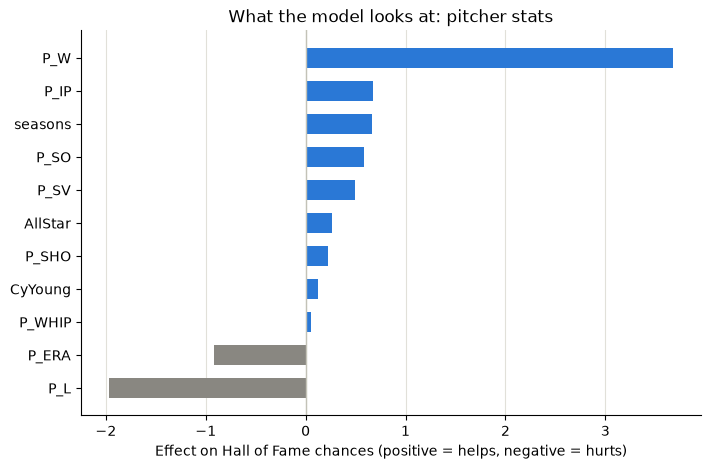

In [51]:
#step 6d: which stats does the pitcher model rely on most?
p_coefs = pd.Series(p_model[-1].coef_[0], index=p_features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(p_coefs.index, p_coefs.values, color=["#898781" if v < 0 else "#2a78d6" for v in p_coefs.values], height=0.6)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Effect on Hall of Fame chances (positive = helps, negative = hurts)")
ax.set_title("What the model looks at: pitcher stats")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

**What this step did:** It charted how much weight the pitcher model gives each stat. Blue bars push a pitcher's score up and gray bars pull it down, with everything else held the same.

**Result:**
- **Wins dominate (3.67).** Wins count more than five times as much as any other stat that helps. For most of history, Hall of Fame voters judged pitchers by wins first. That's why 300 wins was almost a guaranteed ticket in (step 4b).
- **Innings pitched (0.68), seasons (0.66), strikeouts (0.58) and saves (0.50)** help a moderate amount. A long career with lots of strikeouts adds to a pitcher's case.
- **ERA (−0.92)** is gray because a *lower* ERA is better, so a higher ERA lowers the score.
- **Losses (−1.97) are gray, but that doesn't mean losses alone keep pitchers out.** Like home runs in the hitter model, losses overlap with wins: pitchers with long careers pile up both. The negative bar means: *between two pitchers with the same number of wins, the one with more losses (a weaker win-loss record) looks less Hall-worthy.*
- **Cy Young awards (0.13), shutouts (0.23) and WHIP (0.06)** barely count. The Cy Young only started in 1956, and many pitchers in the training set retired before then, so the model had little chance to learn its value.

**In plain terms:** The pitcher model mostly asks, *"How many games did this pitcher win, and how good was the win-loss record?"* That works well for starting pitchers, but it's a problem for closers, who rarely get wins (see step 6e).

In [52]:
#step 6e: look at the test pitchers the model got wrong, and how close the calls were
p_show_cols = ["nameFirst", "nameLast", "last_year", "P_W", "P_SV", "P_SO", "P_ERA", "AllStar", "CyYoung", "probability"]

print("Highest-rated pitchers who did NOT make it (false alarms):")
display(p_test[p_test["inducted"] == 0].sort_values("probability", ascending=False)[p_show_cols].head(10).round(3))

print("Lowest-rated pitchers who DID make it:")
display(p_test[p_test["inducted"] == 1].sort_values("probability")[p_show_cols].head(5).round(3))

print("How many pitchers the model flags at different probability cutoffs:")
p_cutoffs = []
for cutoff in [0.5, 0.7, 0.8, 0.9]:
    flagged = p_test[p_test["probability"] >= cutoff]
    p_cutoffs.append({
        "Cutoff": f"{cutoff:.0%}",
        "Pitchers flagged": len(flagged),
        "Actually inducted": flagged["inducted"].sum(),
        "Hall of Famers missed": p_test["inducted"].sum() - flagged["inducted"].sum(),
    })
display(pd.DataFrame(p_cutoffs).set_index("Cutoff"))

Highest-rated pitchers who did NOT make it (false alarms):


,nameFirst,nameLast,last_year,P_W,P_SV,P_SO,P_ERA,AllStar,CyYoung,probability
playerID,,,,,,,,,,
johnto01,Tommy,John,1989,288.0,4.0,2245.0,3.342,4,0,0.998
schilcu01,Curt,Schilling,2007,216.0,22.0,3116.0,3.458,6,0,0.989
martide01,Dennis,Martinez,1998,245.0,8.0,2149.0,3.697,4,0,0.973
brownke01,Kevin,Brown,2005,211.0,0.0,2397.0,3.275,6,0,0.964
wellsda01,David,Wells,2007,239.0,13.0,2201.0,4.130,3,0,0.944
coneda01,David,Cone,2003,194.0,1.0,2668.0,3.462,5,1,0.942
francjo01,John,Franco,2005,90.0,424.0,975.0,2.890,4,0,0.941
bluevi01,Vida,Blue,1986,209.0,2.0,2175.0,3.265,6,1,0.936
goodedw01,Dwight,Gooden,2000,194.0,3.0,2293.0,3.506,4,1,0.923


Lowest-rated pitchers who DID make it:


,nameFirst,nameLast,last_year,P_W,P_SV,P_SO,P_ERA,AllStar,CyYoung,probability
playerID,,,,,,,,,,
suttebr01,Bruce,Sutter,1988,68.0,300.0,861.0,2.833,6,1,0.258
smithle02,Lee,Smith,1997,71.0,478.0,1251.0,3.029,7,0,0.895
wagnebi02,Billy,Wagner,2010,47.0,422.0,1196.0,2.312,6,0,0.911
morrija02,Jack,Morris,1994,254.0,0.0,2478.0,3.900,5,0,0.958
gossari01,Rich,Gossage,1994,124.0,310.0,1502.0,3.009,9,0,0.979


How many pitchers the model flags at different probability cutoffs:


,Pitchers flagged,Actually inducted,Hall of Famers missed
Cutoff,,,
50%,42,18,1
70%,35,18,1
80%,32,18,1
90%,26,17,2


**What this step did:** It looked at the pitcher model's mistakes and close calls, then tested stricter cutoffs.

**Result: the biggest false alarms**

The pitchers the model rated highest who *didn't* get in:
- **Tommy John (0.998):** 288 wins, close to the 300 mark. His best showing with the writers was 32%, and a committee gave him 44% in 2025. (Yes, the elbow surgery is named after him.)
- **Curt Schilling (0.989):** 3,116 strikeouts and a strong postseason record. He reached **71%** of the writers' vote in 2021, just short of 75%, then dropped as voters reacted to his public comments after retiring. That's a factor the model can't see.
- **Kevin Brown (0.964):** Named in the Mitchell Report on PEDs. He isn't on our exclusion list, but voters treated him like he was. It may be worth adding him.
- **Dwight Gooden (0.923):** A dominant start to his career, cut short by drug suspensions.
- **Dennis Martínez, David Wells, David Cone, Vida Blue, Bob Welch:** Very good starters with 190–245 wins. This is the "Hall of Very Good" for pitchers.
- **John Franco (0.941):** 424 saves, but voters have not been kind to closers (step 4b).

**Result: the Hall of Famers the model struggled with**

All five are **relief pitchers or borderline starters**:
- **Bruce Sutter (0.26), the one Hall of Famer the model missed.** Sutter was a closer with only 68 wins. Since the model leans heavily on wins, it couldn't see his value. Voters elected him in 2006 mostly for popularizing the split-finger fastball and dominating as a reliever.
- **Lee Smith (0.90), Billy Wagner (0.91) and Goose Gossage (0.98):** also closers. Wagner got in on his **10th and final** writers' ballot in 2025, and Smith was elected by a committee.
- **Jack Morris (0.96):** a starter with a high 3.90 ERA, elected by a committee in 2018 after falling short with the writers.

**Result: raising the cutoff**

| Cutoff | Pitchers flagged | Actually inducted | Hall of Famers missed |
|---|---|---|---|
| 50% | 42 | 18 | 1 |
| 70% | 35 | 18 | 1 |
| 80% | 32 | 18 | 1 |
| 90% | 26 | 17 | 2 |

As with hitters, **80%** works best: false alarms drop from 24 to 14 with no extra misses. Sutter is missed at every cutoff because his score is so low.

**In plain terms:** The pitcher model is built around wins, so it underrates **closers**, and it can't see the reputation or off-field issues that cost Schilling, Brown and Gooden votes.

In [53]:
#step 6f: predict the pitchers who retired after 2010 and whose fate is still being decided
p_pending = p_pending.assign(probability=p_model.predict_proba(p_pending[p_features])[:, 1])
p_pending_cols = ["nameFirst", "nameLast", "last_year", "P_W", "P_SV", "P_SO", "P_ERA", "AllStar", "CyYoung", "inducted", "probability"]
p_pending.sort_values("probability", ascending=False)[p_pending_cols].head(15).round(3)

,nameFirst,nameLast,last_year,P_W,P_SV,P_SO,P_ERA,AllStar,CyYoung,inducted,probability
playerID,,,,,,,,,,,
riverma01,Mariano,Rivera,2013,82.0,652.0,1173.0,2.209,13,0,1,1.000
sabatcc01,CC,Sabathia,2019,251.0,0.0,3093.0,3.736,6,1,1,0.995
hallaro01,Roy,Halladay,2013,203.0,1.0,2117.0,3.385,8,2,1,0.984
moyerja01,Jamie,Moyer,2012,269.0,0.0,2441.0,4.255,1,0,0,0.962
colonba01,Bartolo,Colon,2018,247.0,0.0,2535.0,4.118,4,1,0,0.946
hudsoti01,Tim,Hudson,2015,222.0,0.0,2080.0,3.492,4,0,0,0.937
nathajo01,Joe,Nathan,2016,64.0,377.0,976.0,2.866,6,0,0,0.849
rodrifr03,Francisco,Rodriguez,2017,52.0,437.0,1142.0,2.859,6,0,0,0.806
buehrma01,Mark,Buehrle,2015,214.0,0.0,1870.0,3.813,5,0,0,0.601


**What this step did:** It used the pitcher model on the 208 pitchers who retired after 2010 and listed the 15 it rates highest. The `inducted` column shows who has already made it (1) and who hasn't yet (0).

**Result: the model agrees with the voters**

All 3 pitchers in this group who have been inducted are the model's **top 3**:
- **Mariano Rivera (1.00):** the all-time saves leader (652). He was the first player ever elected **unanimously**. His 652 saves were enough to overcome the model's focus on wins.
- **CC Sabathia (0.995):** 251 wins and 3,093 strikeouts, elected in 2025
- **Roy Halladay (0.98):** 2 Cy Young awards, elected in 2019

**Result: where the model and voters disagree**

The model rates these pitchers highly, but voters gave them very little support:
- **Jamie Moyer (0.96), Bartolo Colón (0.95) and Tim Hudson (0.94):** All three won 220–270 games over very long careers. Moyer and Colón each got under 3% of the vote and were dropped after one ballot. Hudson lasted two. These pitchers were good for a long time, but rarely among the best, and voters care about that difference. The model, built around wins, doesn't.
- **Joe Nathan (0.85) and Francisco Rodríguez (0.81):** closers with 377 and 437 saves. Nathan was dropped after one ballot, and Rodríguez is getting about 10%.
- **Félix Hernández (0.58):** a Cy Young winner who dominated at his peak but finished with only 169 wins. He got 21% in his first year on the ballot (2025), which is a reasonable start for a player whose case rests on his peak.

**In plain terms:** The model correctly ranks the three recent Hall of Fame pitchers at the top. Below them, it confuses "**pitched a long time**" with "**was one of the best**." Modern voters care more about how dominant a pitcher was than about total wins, so a model built on win totals overrates pitchers who lasted a long time and underrates dominant pitchers with shorter careers.

In [54]:
#step 7a: train gradient boosting models for hitters and pitchers on the same training data
from sklearn.ensemble import HistGradientBoostingClassifier

#conservative settings for a small dataset: shallow trees, a slow learning rate, and at least 20 players per leaf
boost_settings = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=20,
                      class_weight="balanced", random_state=42)

boost_model = HistGradientBoostingClassifier(**boost_settings).fit(train[features], train["inducted"])
p_boost_model = HistGradientBoostingClassifier(**boost_settings).fit(p_train[p_features], p_train["inducted"])

#score the test and not-yet-decided players with the boosting models
test["boost_probability"] = boost_model.predict_proba(test[features])[:, 1]
p_test["boost_probability"] = p_boost_model.predict_proba(p_test[p_features])[:, 1]
pending["boost_probability"] = boost_model.predict_proba(pending[features])[:, 1]
p_pending["boost_probability"] = p_boost_model.predict_proba(p_pending[p_features])[:, 1]

print("Boosting models trained for hitters and pitchers")

Boosting models trained for hitters and pitchers


**What this step did:** It trained a second kind of model, **gradient boosting**, for both hitters and pitchers. It used the exact same training players and stats as steps 5 and 6, so the comparison is fair.

**How boosting is different from logistic regression:**
- **Logistic regression** gives each stat one fixed weight and adds them up, like a point system: "each RBI is worth X points."
- **Gradient boosting** builds hundreds of small **decision trees**, each a short chain of yes/no questions like *"More than 1,200 RBI? More than 5 All-Star selections?"* Each new tree tries to fix the mistakes of the trees before it. This lets boosting find **thresholds** and **combinations** that a point system can't, for example "lots of RBI only matter if the player was also an All-Star."

The settings are deliberately **cautious** (shallow trees, slow learning, at least 20 players per final group). With only a few hundred Hall of Famers, a more aggressive model would memorize the training players instead of learning general patterns.

**Result:** No table yet; this step only builds the two models and scores every player. The comparison is in the next step.

In [55]:
#step 7b: compare logistic regression and boosting side by side on the test players
comparison = []
for group, df in [("Hitters", test), ("Pitchers", p_test)]:
    for model_name, column in [("Logistic regression", "probability"), ("Gradient boosting", "boost_probability")]:
        row = {"Group": group, "Model": model_name,
               "PR-AUC": round(average_precision_score(df["inducted"], df[column]), 3)}
        for cutoff in [0.5, 0.8]:
            flagged = df[column] >= cutoff
            row[f"Found at {cutoff:.0%}"] = f"{(flagged & (df['inducted'] == 1)).sum()} of {df['inducted'].sum()}"
            row[f"False alarms at {cutoff:.0%}"] = (flagged & (df["inducted"] == 0)).sum()
        comparison.append(row)

pd.DataFrame(comparison).set_index(["Group", "Model"])

PR-AUC Found at 50%  False alarms at 50%  \
Group    Model                                                           
Hitters  Logistic regression   0.911     35 of 35                   64   
         Gradient boosting     0.906     34 of 35                   29   
Pitchers Logistic regression   0.902     18 of 19                   24   
         Gradient boosting     0.911     18 of 19                   10   

                             Found at 80%  False alarms at 80%  
Group    Model                                                  
Hitters  Logistic regression     35 of 35                   28  
         Gradient boosting       32 of 35                   14  
Pitchers Logistic regression     18 of 19                   14  
         Gradient boosting       16 of 19                    7

**What this step did:** It compared the two kinds of models on the same test players (who retired 1986–2010), at two cutoffs: the default **50%**, and the stricter **80%** that worked best in steps 5e and 6e.

**Result:**

| | Model | PR-AUC | Found at 50% | False alarms at 50% | Found at 80% | False alarms at 80% |
|---|---|---|---|---|---|---|
| **Hitters** | Logistic regression | **0.911** | **35 of 35** | 64 | **35 of 35** | 28 |
| | Gradient boosting | 0.906 | 34 of 35 | 29 | 32 of 35 | **14** |
| **Pitchers** | Logistic regression | 0.902 | 18 of 19 | 24 | 18 of 19 | 14 |
| | Gradient boosting | **0.911** | 18 of 19 | **10** | 16 of 19 | 7 |

**How to read this:**
- **PR-AUC (overall ranking quality) is essentially a tie.** The differences (0.911 vs 0.906, 0.902 vs 0.911) are too small to matter with this few Hall of Famers in the test set.
- **At 50%, boosting looks much better**: it cuts false alarms in half. But that's mostly because boosting is **naturally stricter**, not because it's smarter.
- **The fair comparison** is logistic regression at 80% vs boosting at 50%, since both say "yes" to about the same number of players:
  - **Hitters:** Logistic regression finds 35 with 28 false alarms; boosting finds 34 with 29. **A tie.**
  - **Pitchers:** Logistic regression finds 18 with 14 false alarms; boosting finds 18 with 10. **A small win for boosting.**

**In plain terms:** Boosting is **not clearly better**. Logistic regression, with the right cutoff, does just as well for hitters and nearly as well for pitchers, and it's much easier to explain. This is common with small datasets: a simple model with good features is often as good as a complex one.

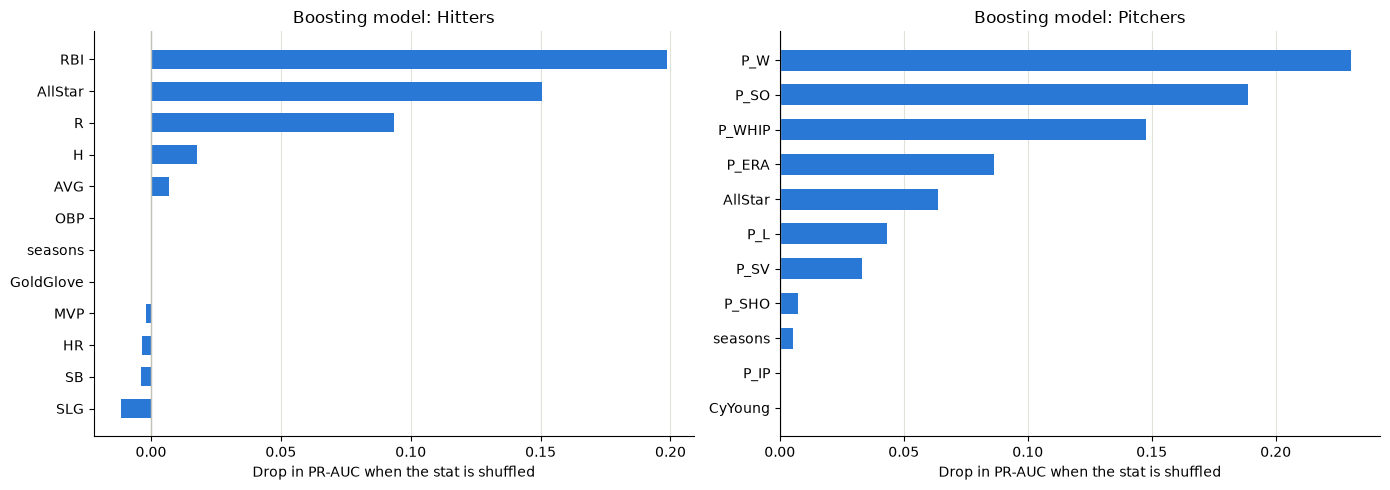

In [56]:
#step 7c: which stats does each boosting model rely on? (permutation importance)
from sklearn.inspection import permutation_importance

#shuffle one stat at a time and measure how much worse the model gets; a bigger drop means the stat matters more
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (title, fitted, df, cols) in zip(axes, [
    ("Hitters", boost_model, test, features),
    ("Pitchers", p_boost_model, p_test, p_features),
]):
    result = permutation_importance(fitted, df[cols], df["inducted"], scoring="average_precision",
                                    n_repeats=20, random_state=42)
    importance = pd.Series(result.importances_mean, index=cols).sort_values()
    ax.barh(importance.index, importance.values, color="#2a78d6", height=0.6)
    ax.axvline(0, color="#c3c2b7", linewidth=1)
    ax.set_title(f"Boosting model: {title}")
    ax.set_xlabel("Drop in PR-AUC when the stat is shuffled")
    ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

**What this step did:** Boosting doesn't give each stat a simple weight like logistic regression does, so this step used a different method to see what it relies on: **permutation importance**. It scrambles one stat at a time (shuffles it randomly between players) and checks how much worse the model gets. If scrambling a stat hurts a lot, the model depends on it. If nothing changes, the model ignores it.

**Result: hitters**
- The boosting model depends almost entirely on **RBI**, **All-Star selections** and **runs scored**. Hits and batting average add a little.
- It **ignores** OBP, seasons played, Gold Gloves, MVPs, home runs, stolen bases and slugging. Scrambling them changes nothing, or even helps slightly (the small bars below zero are just random noise).
- Compared with logistic regression, which spread weight across 12 stats, boosting focuses on just **three**.

**Result: pitchers**
- **Wins** still matter most, but less overwhelmingly than in the logistic regression model.
- **Strikeouts, WHIP and ERA** matter much more here. Boosting pays more attention to how *dominant* a pitcher was, not just how long they pitched.
- Saves matter only a little, and Cy Young awards not at all.

**In plain terms:** The two kinds of models tell a similar story: **production (RBI, runs, wins) plus recognition (All-Star selections)** is what gets players in. Boosting gets there with fewer stats.

In [57]:
#step 7d: where do the two models disagree most on the test players?
for group, df in [("Hitters", test), ("Pitchers", p_test)]:
    df = df.assign(difference=df["boost_probability"] - df["probability"])
    cols = ["nameFirst", "nameLast", "inducted", "probability", "boost_probability", "difference"]
    print(f"{group}: boosting rates much LOWER than logistic regression")
    display(df.sort_values("difference")[cols].head(6).round(3))
    print(f"{group}: boosting rates much HIGHER than logistic regression")
    display(df.sort_values("difference", ascending=False)[cols].head(6).round(3))

Hitters: boosting rates much LOWER than logistic regression


,nameFirst,nameLast,inducted,probability,boost_probability,difference
playerID,,,,,,
cedence01,Cesar,Cedeno,0,0.924,0.166,-0.758
cruzjo01,Jose,Cruz,0,0.815,0.083,-0.732
whitalo01,Lou,Whitaker,0,0.899,0.189,-0.711
mcraeha01,Hal,McRae,0,0.767,0.115,-0.652
mcgeewi01,Willie,McGee,0,0.958,0.308,-0.650
wilsowi02,Willie,Wilson,0,0.779,0.130,-0.649


Hitters: boosting rates much HIGHER than logistic regression


,nameFirst,nameLast,inducted,probability,boost_probability,difference
playerID,,,,,,
cartejo01,Joe,Carter,0,0.404,0.837,0.433
belleal01,Albert,Belle,0,0.619,0.949,0.330
delgaca01,Carlos,Delgado,0,0.707,0.946,0.239
strawda01,Darryl,Strawberry,0,0.559,0.760,0.201
kingmda01,Dave,Kingman,0,0.031,0.197,0.166
garcino01,Nomar,Garciaparra,0,0.771,0.913,0.142


Pitchers: boosting rates much LOWER than logistic regression


,nameFirst,nameLast,inducted,probability,boost_probability,difference
playerID,,,,,,
houghch01,Charlie,Hough,0,0.836,0.127,-0.709
francjo01,John,Franco,0,0.941,0.243,-0.699
saberbr01,Bret,Saberhagen,0,0.602,0.044,-0.558
reussje01,Jerry,Reuss,0,0.838,0.317,-0.521
keyji01,Jimmy,Key,0,0.529,0.029,-0.501
stiebda01,Dave,Stieb,0,0.526,0.033,-0.493


Pitchers: boosting rates much HIGHER than logistic regression


,nameFirst,nameLast,inducted,probability,boost_probability,difference
playerID,,,,,,
langsma01,Mark,Langston,0,0.233,0.419,0.186
wagnebi02,Billy,Wagner,1,0.911,0.977,0.066
morrija02,Jack,Morris,1,0.958,0.979,0.021
wellsda01,David,Wells,0,0.944,0.964,0.020
belchti01,Tim,Belcher,0,0.007,0.019,0.012
mulhote01,Terry,Mulholland,0,0.005,0.013,0.009


**What this step did:** It found the test players where the two models disagree the most. This shows *how* they think differently.

**Result: hitters that boosting rates much lower**
**César Cedeño, José Cruz, Lou Whitaker, Hal McRae, Willie McGee and Willie Wilson** all had long, solid careers but never piled up big RBI totals (most finished under about 1,100). Logistic regression gave them credit for many decent stats added together. Boosting says *"no big RBI total, not a Hall of Famer."* None of them were inducted, so **boosting is right here**.

**Result: hitters that boosting rates much higher**
**Joe Carter, Albert Belle, Carlos Delgado and Nomar Garciaparra** were feared hitters with big RBI totals or All-Star résumés, but none of them made it. Belle and Garciaparra had short careers (Belle played 12 seasons) cut short by injuries. Boosting's focus on RBI overrates them, and it ignores seasons played, so it can't tell that their careers were short. **Logistic regression is right here.**

**Result: pitchers that boosting rates much lower**
**Charlie Hough** (216 wins *and* 216 losses), **Bret Saberhagen, Jimmy Key, Dave Stieb** and closer **John Franco** were rated much lower by boosting. None of them were inducted, so boosting cut these false alarms correctly.

**The catch: boosting is even harder on closers.** It gives **Bruce Sutter 0.15**, **Lee Smith 0.54** and **Goose Gossage 0.70**, all lower than logistic regression did, and all three are in the Hall. Boosting also gives **Alan Trammell only 0.32**: Trammell, a shortstop who was elected by a committee, had only 1,003 RBI.

**In plain terms:** Boosting is better at saying "no" to players who were just *consistent*, but worse at spotting Hall of Famers whose case wasn't built on big totals (closers, great defenders, players elected late by committees).

In [58]:
#step 7e: compare predictions for players whose Hall of Fame fate is still being decided
pending_compare = ["nameFirst", "nameLast", "inducted", "probability", "boost_probability"]

print("Hitters (retired after 2010), sorted by boosting score")
display(pending.sort_values("boost_probability", ascending=False)[pending_compare].head(15).round(3))

print("Pitchers (retired after 2010), sorted by boosting score")
display(p_pending.sort_values("boost_probability", ascending=False)[pending_compare].head(10).round(3))

Hitters (retired after 2010), sorted by boosting score


,nameFirst,nameLast,inducted,probability,boost_probability
playerID,,,,,
guerrvl01,Vladimir,Guerrero,1,0.994,1.000
heltoto01,Todd,Helton,1,0.989,0.999
ortizda01,David,Ortiz,1,0.982,0.999
jonesch06,Chipper,Jones,1,0.998,0.997
suzukic01,Ichiro,Suzuki,1,0.999,0.997
jeterde01,Derek,Jeter,1,1.000,0.997
beltrca01,Carlos,Beltran,0,0.988,0.996
rodriiv01,Ivan,Rodriguez,1,1.000,0.993
berkmla01,Lance,Berkman,0,0.894,0.989


Pitchers (retired after 2010), sorted by boosting score


,nameFirst,nameLast,inducted,probability,boost_probability
playerID,,,,,
moyerja01,Jamie,Moyer,0,0.962,0.990
sabatcc01,CC,Sabathia,1,0.995,0.986
riverma01,Mariano,Rivera,1,1.000,0.985
colonba01,Bartolo,Colon,0,0.946,0.965
hallaro01,Roy,Halladay,1,0.984,0.939
rodrifr03,Francisco,Rodriguez,0,0.806,0.928
nathajo01,Joe,Nathan,0,0.849,0.787
hamelco01,Cole,Hamels,0,0.440,0.709
wakefti01,Tim,Wakefield,0,0.178,0.648


**What this step did:** It compared the two models' predictions for players who retired after 2010, whose fate is still being decided. The table is sorted by the boosting score.

**Result: hitters**
- **Both models agree on the top.** Every inducted player in this group still ranks near the top, and **Carlos Beltrán** stays at **0.99+** with both models. Both models think he'll get in.
- **Lance Berkman** jumps from 0.89 to **0.99** with boosting. Berkman got only 1.2% of the vote in his single year on the ballot (2019), so this is a clear **boosting mistake**. Boosting sees his 1,234 RBI and 6 All-Star selections and gives full credit, but he finished with only 1,905 hits, and voters saw a very good hitter, not a Hall of Famer.
- **Omar Vizquel** drops from 0.99 to 0.89, since he had a weak RBI total. His real support collapsed for off-field reasons, which neither model can see.
- **Andruw Jones** (not shown in the top 15) drops from 0.77 to **0.65**. Boosting completely ignores Gold Gloves, and defense is his whole case.

**Result: pitchers**
- Rivera, Sabathia and Halladay (all inducted) are still near the top.
- **Jamie Moyer** is now rated **first** (0.99), even higher than with logistic regression. Boosting doesn't fix the "long career = Hall of Famer" problem for pitchers. Moyer got 2.4% of the vote and was dropped after one year.

**Overall conclusion from step 7:**
- **Neither model is clearly better.** They're about equally accurate overall.
- **Logistic regression** is easier to explain and handles unusual careers (closers, great defenders, players elected late by committees) a little better.
- **Gradient boosting** gives fewer false alarms at the same cutoff, especially for pitchers, but leans on just a few stats and makes some odd calls (Berkman, Moyer).
- **The bigger opportunity is better data, not a fancier model.** Neither model knows a player's position, peak seasons, postseason play or off-field issues. Adding stats like these would likely help more than switching models.

In [59]:
#step 8a: find players who are still active or retired too recently to be on the ballot yet

#players must wait 5 years after their last season, so anyone whose last season was after 2020 isn't eligible yet
future = career[career["last_year"] > last_data_year - 5].copy()
future["status"] = future["last_year"].map(lambda year: "Played in 2025" if year == last_data_year else f"Last played {year}")

#recent players suspended for PEDs, kept out for the same reason as the players in step 5a
recent_ped_players = ["canoro01", "cruzne02", "martest01"]
future = future[~future.index.isin(excluded | set(recent_ped_players))]

#need at least 5 seasons to have a career worth scoring
future = future[future["seasons"] >= 5]

future_hitters = future[~future["is_pitcher"]].dropna(subset=features)
future_pitchers = future[future["is_pitcher"]].dropna(subset=p_features)

print(f"Players who are active or not yet eligible (5+ seasons): {len(future):,}")
print(f"  Hitters scored:  {len(future_hitters):,}")
print(f"  Pitchers scored: {len(future_pitchers):,}")
print(f"  Played in 2025:  {(future['last_year'] == last_data_year).sum():,}")

Players who are active or not yet eligible (5+ seasons): 1,183
  Hitters scored:  538
  Pitchers scored: 645
  Played in 2025:  620


**What this step did:** It found the players the models haven't seen yet: those who are **still playing** or who **retired too recently** to be on the ballot. A player has to wait 5 years after their last season, so anyone who last played after 2020 isn't eligible yet.

It applied the same rules as before:
- The PED and banned players from step 5a are left out. Three more recent players who were **suspended for PEDs** are also left out: **Robinson Canó, Nelson Cruz and Starling Marte**.
- Only players with at least **5 seasons** are scored, since shorter careers are too early to judge.

**Result:**
- **1,183** players qualify: **538 hitters** and **645 pitchers**.
- **620** of them played in 2025.

**One big caveat about active players:** The models score career totals *so far*. For a player still in the middle of a career, the score really means *"Would they make the Hall of Fame if they retired today?"* Young stars will gain hits, wins and awards over time, so their scores will likely go up.

**A data limit:** The data can't tell whether a player has retired, only their last season. "Last played 2024" usually means retired, but could also mean the player missed 2025 with an injury.

In [60]:
#step 8b: score future hitters with both models and sort them into tiers
def hof_tier(score):
    #80% is the cutoff that worked best in steps 5e and 6e
    if score >= 0.8:
        return "Strong candidate"
    if score >= 0.5:
        return "Borderline"
    return "Long shot (so far)"

future_hitters = future_hitters.assign(
    probability=model.predict_proba(future_hitters[features])[:, 1],
    boost_probability=boost_model.predict_proba(future_hitters[features])[:, 1],
)
future_hitters["tier"] = future_hitters["probability"].map(hof_tier)

hitter_cols = ["nameFirst", "nameLast", "status", "seasons", "H", "HR", "RBI", "AVG", "AllStar", "MVP",
               "probability", "boost_probability", "tier"]
future_hitters.sort_values("probability", ascending=False)[hitter_cols].head(25).round(3)

,nameFirst,nameLast,status,seasons,H,HR,RBI,AVG,AllStar,MVP,probability,boost_probability,tier
playerID,,,,,,,,,,,,,
pujolal01,Albert,Pujols,Last played 2022,22,3384,703,2218.0,0.296,11,3,1.000,1.000,Strong candidate
cabremi01,Miguel,Cabrera,Last played 2023,21,3174,511,1881.0,0.306,12,2,1.000,0.999,Strong candidate
troutmi01,Mike,Trout,Played in 2025,15,1754,404,1018.0,0.294,11,3,0.998,0.998,Strong candidate
freemfr01,Freddie,Freeman,Played in 2025,16,2431,367,1322.0,0.300,9,1,0.991,0.991,Strong candidate
judgeaa01,Aaron,Judge,Played in 2025,10,1205,368,830.0,0.294,7,3,0.979,0.968,Strong candidate
goldspa01,Paul,Goldschmidt,Played in 2025,15,2190,372,1232.0,0.288,7,1,0.977,0.887,Strong candidate
vottojo01,Joey,Votto,Last played 2023,17,2135,356,1144.0,0.294,6,1,0.974,0.925,Strong candidate
altuvjo01,Jose,Altuve,Played in 2025,15,2388,255,889.0,0.303,9,1,0.973,0.979,Strong candidate
harpebr03,Bryce,Harper,Played in 2025,14,1801,363,1051.0,0.280,8,2,0.971,0.946,Strong candidate


**What this step did:** It scored every future hitter with **both** models (logistic regression and boosting) and sorted them into tiers based on the logistic regression score, the main model:
- **Strong candidate:** 80% or higher, the cutoff that worked best in step 5e
- **Borderline:** 50–80%
- **Long shot (so far):** under 50%

**Result: near-locks.** **Albert Pujols** (703 home runs, 3,384 hits) and **Miguel Cabrera** (a Triple Crown, 3,174 hits, 511 home runs) score **1.00** with both models. They're the closest thing to sure picks. Pujols first becomes eligible in 2028 and Cabrera in 2029.

**Result: strong candidates still playing.** **Mike Trout** (0.998, 3 MVPs), **Freddie Freeman**, **Aaron Judge**, **Paul Goldschmidt**, **José Altuve**, **Bryce Harper** and **Mookie Betts** all score above 0.95, *even based only on what they've done so far*. **Altuve** may face the same kind of voter resistance as Carlos Beltrán, since both played for the 2017 Astros in the sign-stealing scandal.

**Result: where the models disagree.**
- **Shohei Ohtani:** logistic regression **0.96**, boosting **0.06**. Logistic regression gives heavy credit for his **4 MVPs**. Boosting relies mostly on RBI totals, and Ohtani has only 669 so far. Neither model counts his **pitching**, because he's classified as a hitter. He's the hardest player in baseball for any stats model to judge.
- **Buster Posey:** logistic regression 0.76 (borderline), boosting 0.08. Posey was a catcher with a short career (12 seasons), which hurts his totals. Voters may still give him credit for 3 World Series titles and an MVP, which the model only partly sees.
- **Andrew McCutchen:** 0.91 vs 0.46. A very good, long career, but this is the "Hall of Very Good" pattern the logistic regression model has overrated before.

**Result: young stars who aren't there yet.** **Ronald Acuña Jr.** (0.37) and **Juan Soto** (not in the top 25, about 0.24) have only 8 seasons each. Their totals are far from complete, so their scores should rise a lot if they keep playing at their current level.

In [61]:
#step 8c: score future pitchers with both models and sort them into tiers
future_pitchers = future_pitchers.assign(
    probability=p_model.predict_proba(future_pitchers[p_features])[:, 1],
    boost_probability=p_boost_model.predict_proba(future_pitchers[p_features])[:, 1],
)
future_pitchers["tier"] = future_pitchers["probability"].map(hof_tier)

pitcher_cols = ["nameFirst", "nameLast", "status", "seasons", "P_W", "P_SV", "P_SO", "P_ERA", "AllStar", "CyYoung",
                "probability", "boost_probability", "tier"]
future_pitchers.sort_values("probability", ascending=False)[pitcher_cols].head(15).round(3)

,nameFirst,nameLast,status,seasons,P_W,P_SV,P_SO,P_ERA,AllStar,CyYoung,probability,boost_probability,tier
playerID,,,,,,,,,,,,,
kershcl01,Clayton,Kershaw,Played in 2025,18,223.0,0.0,3052.0,2.534,11,3,1.000,0.997,Strong candidate
verlaju01,Justin,Verlander,Played in 2025,20,266.0,0.0,3553.0,3.322,9,3,1.000,0.998,Strong candidate
scherma01,Max,Scherzer,Played in 2025,18,221.0,0.0,3489.0,3.217,8,3,0.999,0.996,Strong candidate
greinza01,Zack,Greinke,Last played 2023,20,225.0,1.0,2979.0,3.492,4,1,0.983,0.935,Strong candidate
janseke01,Kenley,Jansen,Played in 2025,16,54.0,476.0,1278.0,2.572,4,0,0.943,0.926,Strong candidate
kimbrcr01,Craig,Kimbrel,Played in 2025,16,56.0,440.0,1282.0,2.585,9,0,0.941,0.977,Strong candidate
chapmar01,Aroldis,Chapman,Played in 2025,16,60.0,367.0,1331.0,2.520,8,0,0.881,0.977,Strong candidate
lestejo01,Jon,Lester,Last played 2021,16,200.0,0.0,2488.0,3.659,5,0,0.866,0.475,Strong candidate
salech01,Chris,Sale,Played in 2025,15,145.0,12.0,2579.0,3.010,9,1,0.847,0.976,Strong candidate


**What this step did:** It did the same scoring for future pitchers.

**Result: near-locks.** **Clayton Kershaw, Justin Verlander and Max Scherzer** score **1.00** with both models. Each has **3 Cy Young awards** and over **3,000 strikeouts**. **Zack Greinke** (0.98) is close behind.

**Result: closers rate surprisingly well.** **Kenley Jansen** (476 saves), **Craig Kimbrel** (440 saves) and **Aroldis Chapman** score 0.88–0.94. That's a change from earlier steps, where the model *underrated* closers. These three have huge save totals *and* low ERAs, which is enough to overcome the model's focus on wins. Voters have been tough on closers, though (step 4b), so these scores may be too optimistic.

**Result: likely overrated.** **Jon Lester** (0.87) and **Adam Wainwright** (0.83) both reached 200 wins with good but rarely dominant careers. This is the same pattern as Tim Hudson and Mark Buehrle in step 6f, whom the model rated highly but voters didn't support. Boosting gives them both under 0.50.

**Result: where the models disagree.**
- **Jacob deGrom:** logistic regression **0.19**, boosting **0.79**. deGrom has **2 Cy Young awards** and a 2.57 ERA, but only **96 wins** because of injuries. The logistic regression model, built around wins (step 6d), can't see how dominant he was. Boosting values strikeouts and WHIP more, so it rates him higher. This is one case where boosting is probably right.
- **Gerrit Cole:** 0.62 vs **0.98**. Same story: dominant but with only 153 wins so far. He shows "Last played 2024" because he missed the 2025 season with an injury, not because he retired.

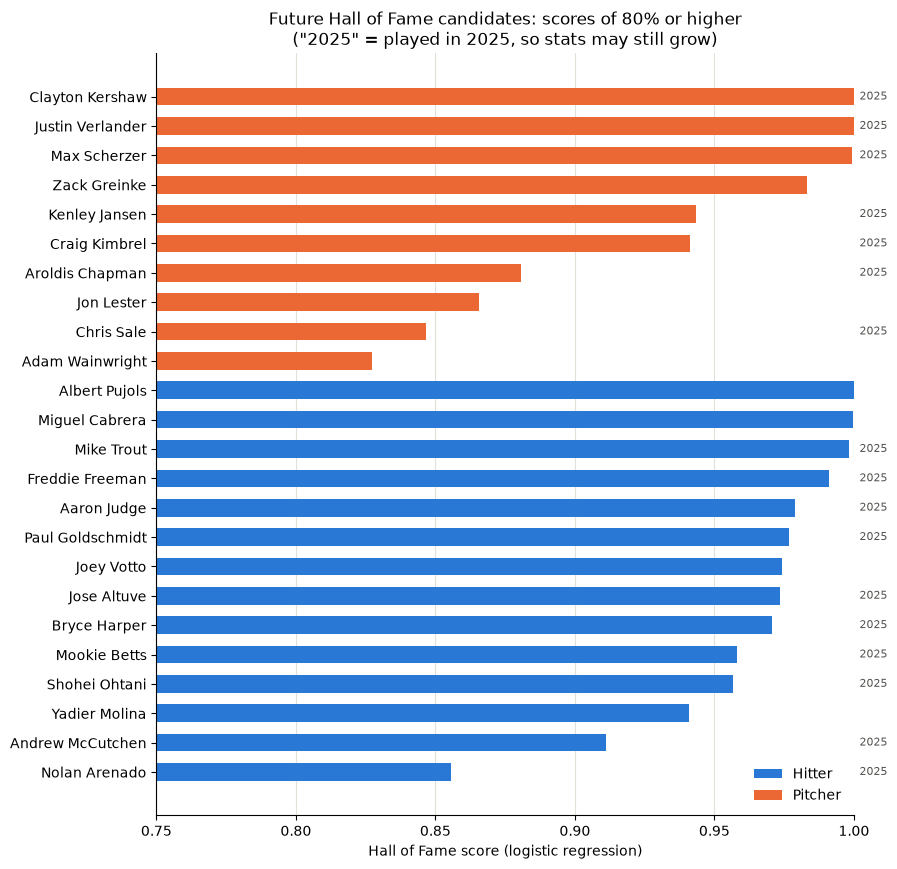

Strong candidates: 24 (14 hitters, 10 pitchers)


In [62]:
#step 8d: chart every strong candidate (score of 80% or higher)
strong = pd.concat([
    future_hitters.assign(role="Hitter"),
    future_pitchers.assign(role="Pitcher"),
])
strong = strong[strong["probability"] >= 0.8].sort_values("probability")
strong["label"] = strong["nameFirst"] + " " + strong["nameLast"]

role_colors = {"Hitter": "#2a78d6", "Pitcher": "#eb6834"}
fig, ax = plt.subplots(figsize=(9, 0.35 * len(strong) + 1.5))
for role, color in role_colors.items():
    group = strong[strong["role"] == role]
    ax.barh(group["label"], group["probability"], color=color, height=0.6, label=role)

#mark players who played in 2025, since their careers (and stats) may still grow
for label, status in zip(strong["label"], strong["status"]):
    if status == "Played in 2025":
        ax.annotate("2025", (1.0, label), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color="#52514e")

ax.set_xlim(0.75, 1.0)
ax.set_xlabel("Hall of Fame score (logistic regression)")
ax.set_title("Future Hall of Fame candidates: scores of 80% or higher\n(\"2025\" = played in 2025, so stats may still grow)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()

print(f"Strong candidates: {len(strong)} ({(strong['role'] == 'Hitter').sum()} hitters, {(strong['role'] == 'Pitcher').sum()} pitchers)")

**What this step did:** It charted every future player with a score of **80% or higher** with the main model. Blue bars are hitters and orange bars are pitchers. A "2025" label means the player was still playing in 2025, so their stats (and score) can still change.

**Result:** **24 strong candidates**: 14 hitters and 10 pitchers.
- **Already retired, near-locks:** Pujols, Cabrera, Greinke, Votto and Molina
- **Still playing and already at Hall level:** Trout, Freeman, Judge, Kershaw, Verlander, Scherzer and others

**How many will actually make it?** Steps 5e and 6e give a guide. At the 80% cutoff, about **56%** of the players the models flagged were actually inducted (35 of 63 hitters and 18 of 32 pitchers). If that holds, roughly **13 of these 24** will make the Hall of Fame. Players still active could add to their case, and new names (like Soto, Acuña or deGrom) could join the list.

**In plain terms:** The models' best bets are the players fans would also pick: **Pujols, Cabrera, Trout, Kershaw, Verlander and Scherzer**. The biggest uncertainties are **Ohtani** (the models can't judge a two-way player), **closers** (voters are tough on them) and **dominant pitchers with low win totals** like deGrom.